# 02 · Preprocessing, Candidate Generation, Labels and Feature Engineering
**Owner:** Monty · **Code:** `pathsnap/` + `scripts/build_dataset.py` · **Partitions:** train (fit), student_test (check)

Pipeline per trip:
1. **Load & clean** (`io.py`): drop NaN rows, sort by time, drop duplicate timestamps. The route is loaded separately (ground truth never enters prediction).
2. **Project** (`geo.py`): per-trip local equirectangular projection → metres.
3. **Candidates** (`candidates.py`): arcs within R = 50 m of each GPS point (top K = 10), using a KD-tree over densified arcs.
4. **Labels** (`labels.py`): monotone DP alignment of GPS points to the ordered route arcs.
5. **Features** (`features.py`): 21 features per (point, candidate) pair.

In [1]:
import os, sys
# run from the repository root regardless of where the notebook lives
_p = os.path.abspath(os.getcwd())
while not os.path.isdir(os.path.join(_p, "pathsnap")):
    _p = os.path.dirname(_p)
os.chdir(_p); sys.path.insert(0, _p)
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("repo root:", os.getcwd())
import folium
from pathsnap.io import load_trip, load_route
from pathsnap.geo import LocalProjection, point_segment, EARTH_R
from pathsnap.features import prepare_trip, build_features, FEATURE_COLUMNS
from pathsnap.labels import align_route
TRIP_DIR = "data/raw/student_test/00000000"
trip = load_trip(TRIP_DIR)
print({k: (v.shape if hasattr(v, "shape") else v) for k, v in trip.items()})

repo root: C:\Users\shrey\OneDrive\Documents\ML Hackathon\PathSnap_7_H


{'trip_id': '00000000', 'track': (2503, 3), 'nodes': (8542, 2), 'arcs': (18196, 2)}


## 1. Projection check: local projection vs haversine
We verify that the per-trip projection gives the same distances as the great-circle (haversine) formula.

In [2]:
def haversine_m(a, b):
    lon1, lat1, lon2, lat2 = map(np.radians, (a[:, 0], a[:, 1], b[:, 0], b[:, 1]))
    h = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
    return 2 * EARTH_R * np.arcsin(np.sqrt(h))
ll = trip["track"][:, :2]
proj = LocalProjection.from_lonlat(ll)
xy = proj.to_xy(ll)
rng = np.random.default_rng(0); i, j = rng.integers(0, len(ll), 2000), rng.integers(0, len(ll), 2000)
d_h = haversine_m(ll[i], ll[j]); d_p = np.hypot(*(xy[i] - xy[j]).T)
rel = np.abs(d_p - d_h) / np.maximum(d_h, 1)
print(f"pairs up to {d_h.max()/1000:.1f} km apart: median rel. error {np.median(rel):.2e}, max {rel.max():.2e} ({np.max(np.abs(d_p-d_h)):.2f} m)")
naive_deg = np.hypot(*(ll[i] - ll[j]).T) * 111_320
print(f"naive 'degrees x 111 km' error: median {np.median(np.abs(naive_deg-d_h)/np.maximum(d_h,1)):.1%}")

pairs up to 47.9 km apart: median rel. error 5.61e-04, max 2.25e-03 (34.94 m)
naive 'degrees x 111 km' error: median 70.4%


Relative error stays around 0.05% (median) and at most about 0.2% even for points about 50 km apart. For the short distances that matter in map-matching (point-to-arc under 100 m) that is centimetres, far below GPS noise. Treating degrees as distances would be badly wrong (about 70% error here at 56° N).

2503 GPS points, 10718 candidate rows, mean 4.3 candidates/point, points with none: 0


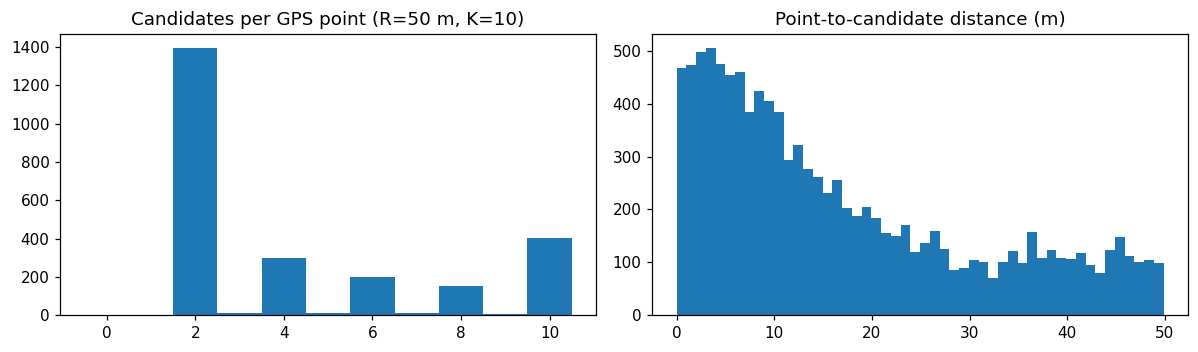

In [3]:
prep = prepare_trip(trip, radius=50.0, k_max=10)
c = prep["cands"]
n_per_obs = np.bincount(c["obs_idx"], minlength=len(prep["pts"]))
print(f"{len(prep['pts'])} GPS points, {len(c['obs_idx'])} candidate rows, mean {n_per_obs.mean():.1f} candidates/point, points with none: {(n_per_obs==0).sum()}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(n_per_obs, bins=np.arange(0, 12) - .5); ax[0].set_title("Candidates per GPS point (R=50 m, K=10)")
ax[1].hist(c["dist_m"], bins=50); ax[1].set_title("Point-to-candidate distance (m)")
plt.tight_layout(); plt.show()

## 3. Labels: aligning GPS points to the reference route
`.route` is ordered **per arc**. We assign each GPS point a route position with a DP that never moves backwards in time:

$$D[i,j] = d(i,j) + \min\big(D[i-1,j],\ \min_{k<j} D[i-1,k] + \lambda (j-k-1)\big)$$

with $d$ the point-to-segment distance (capped at 200 m) and $\lambda = 5$ m per skipped arc. Monotonicity resolves reverse twins and roads visited twice.

route arcs: 179, aligned positions are monotone: True
median distance point -> aligned arc: 6.1 m (p95 16.6 m)
points where plain 'nearest route arc' disagrees with the DP alignment: 0.8%


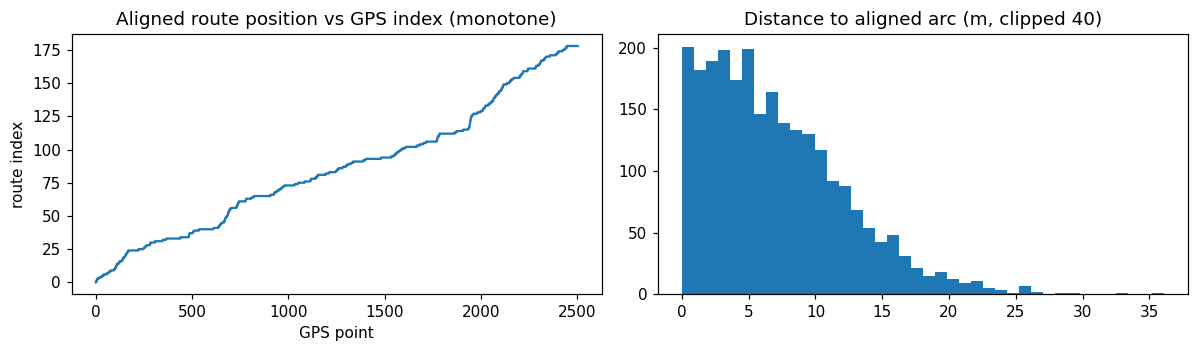

In [4]:
route = load_route(TRIP_DIR)
pos, true_arc, align_d = align_route(prep["net"], prep["pts"], route)
nearest_route = np.array([route[np.argmin(point_segment(np.repeat(p[None], len(route), 0), prep["net"].a_xy[route], prep["net"].b_xy[route])[0])] for p in prep["pts"]])
print(f"route arcs: {len(route)}, aligned positions are monotone: {np.all(np.diff(pos) >= 0)}")
print(f"median distance point -> aligned arc: {np.median(align_d):.1f} m (p95 {np.percentile(align_d,95):.1f} m)")
print(f"points where plain 'nearest route arc' disagrees with the DP alignment: {(nearest_route != true_arc).mean():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(pos); ax[0].set_title("Aligned route position vs GPS index (monotone)"); ax[0].set_xlabel("GPS point"); ax[0].set_ylabel("route index")
ax[1].hist(np.clip(align_d, 0, 40), bins=40); ax[1].set_title("Distance to aligned arc (m, clipped 40)")
plt.tight_layout(); plt.show()

In [5]:
# zoomed Folium view: GPS points, their candidate arcs and the aligned (reference) arc
seg = slice(300, 420)
m = folium.Map(tiles="OpenStreetMap")
to_ll = lambda P: prep["proj"].to_lonlat(P)[:, ::-1]
net = prep["net"]
g_c = folium.FeatureGroup("Candidate arcs")
sel = (c["obs_idx"] >= seg.start) & (c["obs_idx"] < seg.stop)
for a in np.unique(c["cand_arc_id"][sel]):
    folium.PolyLine(to_ll(np.vstack([net.a_xy[a], net.b_xy[a]])).tolist(), color="orange", weight=2).add_to(g_c)
g_t = folium.FeatureGroup("Aligned reference arcs")
for a in np.unique(true_arc[seg]):
    folium.PolyLine(to_ll(np.vstack([net.a_xy[a], net.b_xy[a]])).tolist(), color="green", weight=5).add_to(g_t)
g_g = folium.FeatureGroup("GPS")
for p in to_ll(prep["pts"][seg]): folium.CircleMarker(p.tolist(), radius=2, color="blue").add_to(g_g)
for g in (g_c, g_t, g_g): g.add_to(m)
folium.LayerControl().add_to(m); m.fit_bounds(to_ll(prep["pts"][seg]).tolist())
m.save("results/maps/candidates_and_labels_example.html"); m

## 4. Features
21 features per (point, candidate). None of them uses the route.

In [6]:
df = build_features(prep)
df["label"] = (df.cand_arc_id.values == true_arc[df.obs_idx.values]).astype(int)
groups = {
 "geometric": ["dist_m", "dist_rank", "dist_minus_min", "dist_ratio_min", "n_cands", "proj_frac", "at_endpoint", "arc_length_m"],
 "direction": ["heading_diff", "heading_valid", "heading_cos_x_speed"],
 "kinematics": ["speed_mps", "dt_prev", "gap_flag"],
 "temporal context": ["mean_dist_window", "max_dist_window"],
 "topology": ["prev_best_connected", "next_best_connected", "arc_out_degree", "arc_in_degree", "has_reverse"]}
assert sum(map(len, groups.values())) == len(FEATURE_COLUMNS)
display(pd.DataFrame([(g, f) for g, fs in groups.items() for f in fs], columns=["group", "feature"]).groupby("group").feature.apply(", ".join))
df[["obs_idx", "cand_arc_id", "label"] + FEATURE_COLUMNS].head(10)

group
direction            heading_diff, heading_valid, heading_cos_x_speed
geometric           dist_m, dist_rank, dist_minus_min, dist_ratio_...
kinematics                               speed_mps, dt_prev, gap_flag
temporal context                    mean_dist_window, max_dist_window
topology            prev_best_connected, next_best_connected, arc_...
Name: feature, dtype: object

,obs_idx,cand_arc_id,label,dist_m,dist_rank,dist_minus_min,dist_ratio_min,n_cands,proj_frac,at_endpoint,arc_length_m,heading_diff,heading_valid,heading_cos_x_speed,speed_mps,dt_prev,gap_flag,mean_dist_window,max_dist_window,prev_best_connected,next_best_connected,arc_out_degree,arc_in_degree,has_reverse
0,0,17630,1,6.108905,0,0.000000,0.859331,6,0.872796,0,358.066717,19.793843,1,17.439622,18.534705,0.0,0,5.027721,6.444161,1,1,3,3,1
1,0,17634,0,6.108905,1,0.000000,0.859331,6,0.127204,0,358.066717,160.206157,1,-17.439622,18.534705,0.0,0,5.027721,6.444161,1,1,3,3,1
2,0,17635,0,27.642410,2,21.533505,3.888420,6,0.139866,0,262.481553,155.176982,1,-16.822263,18.534705,0.0,0,22.128663,27.642410,1,0,3,3,1
3,0,17668,0,27.642410,3,21.533505,3.888420,6,0.860134,0,262.481553,24.823018,1,16.822263,18.534705,0.0,0,22.128663,27.642410,0,0,3,3,1
4,0,212,0,45.955327,4,39.846422,6.464473,6,1.000000,1,33.160486,160.092775,1,-17.427167,18.534705,0.0,0,34.593439,45.955327,0,0,3,2,1
5,0,17633,0,45.955327,5,39.846422,6.464473,6,0.000000,1,33.160486,19.907225,1,17.427167,18.534705,0.0,0,34.593439,45.955327,1,0,2,3,1
6,1,17630,1,0.367730,0,0.000000,0.268862,6,0.936786,0,358.066717,7.826849,1,16.161950,16.313929,1.0,0,4.404041,6.444161,1,1,3,3,1
7,1,17634,0,0.367730,1,0.000000,0.268862,6,0.063214,0,358.066717,172.173151,1,-16.161950,16.313929,1.0,0,4.404041,6.444161,1,1,3,3,1
8,1,17635,0,15.636034,2,15.268304,11.432104,6,0.062367,0,262.481553,143.209989,1,-13.064778,16.313929,1.0,0,17.198282,27.642410,1,0,3,3,1
9,1,17668,0,15.636034,3,15.268304,11.432104,6,0.937633,0,262.481553,36.790011,1,13.064778,16.313929,1.0,0,17.198282,27.642410,0,0,3,3,1


## 5. The full dataset (built by `python -m scripts.build_dataset`)

In [7]:
tr = pd.read_parquet("data/processed/train.parquet"); te = pd.read_parquet("data/processed/student_test.parquet")
s_tr = pd.read_csv("results/dataset_summary_train.csv", dtype={"trip_id": str}); s_te = pd.read_csv("results/dataset_summary_student_test.csv", dtype={"trip_id": str})
def miss(s): return (s.candidate_miss_rate * s.n_obs).sum() / s.n_obs.sum()
clean = s_tr[s_tr.median_align_dist_m <= 50]
pd.DataFrame({
  "train (all 80)": [len(s_tr), s_tr.n_obs.sum(), len(tr), tr.label.mean(), miss(s_tr), s_tr.median_align_dist_m.median()],
  "train (clean 78)": [len(clean), clean.n_obs.sum(), int(tr.trip_id.isin(clean.trip_id).sum()), tr[tr.trip_id.isin(clean.trip_id)].label.mean(), miss(clean), clean.median_align_dist_m.median()],
  "student_test": [len(s_te), s_te.n_obs.sum(), len(te), te.label.mean(), miss(s_te), s_te.median_align_dist_m.median()]},
  index=["trips", "GPS points", "candidate rows (train: stride 2)", "positive rate", "candidate miss rate", "median align dist (m)"]).round(4)

,train (all 80),train (clean 78),student_test
trips,80.0000,78.0000,10.0000
GPS points,208417.0000,183260.0000,19160.0000
candidate rows (train: stride 2),646005.0000,587684.0000,131630.0000
positive rate,0.1436,0.1543,0.1451
candidate miss rate,0.1100,0.0106,0.0028
median align dist (m),4.6667,4.6155,4.8163


- **Candidate miss rate** (true arc not in the candidate set, an upper bound on accuracy): 0.3% on student_test and 0.2% on the clean training trips.
- **Positive rate** about 14%: imbalanced, so models use class weighting.
- **Stride 2** on training: consecutive 1 Hz points are near-duplicates, so every 2nd point halves the cost with little information lost. Features still use all neighbours.

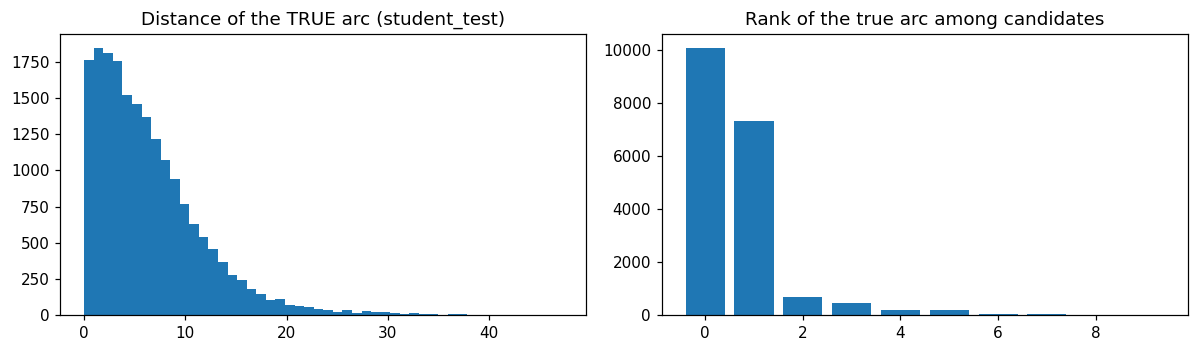

true arc is the nearest candidate only 52.8% of the time -> 'snap to nearest' is not enough
true arc within 25 m: 98.7%, within 50 m: 100.0%


In [8]:
# where does the true arc rank by distance? justifies R=50 m and K=10
pos_rows = te[te.label == 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].hist(np.clip(pos_rows.dist_m, 0, 50), bins=50); ax[0].set_title("Distance of the TRUE arc (student_test)")
ax[1].bar(*np.unique(pos_rows.dist_rank, return_counts=True)); ax[1].set_title("Rank of the true arc among candidates")
plt.tight_layout(); plt.show()
print(f"true arc is the nearest candidate only {np.mean(pos_rows.dist_rank==0):.1%} of the time -> 'snap to nearest' is not enough")
print(f"true arc within 25 m: {np.mean(pos_rows.dist_m<=25):.1%}, within 50 m: {np.mean(pos_rows.dist_m<=50):.1%}")

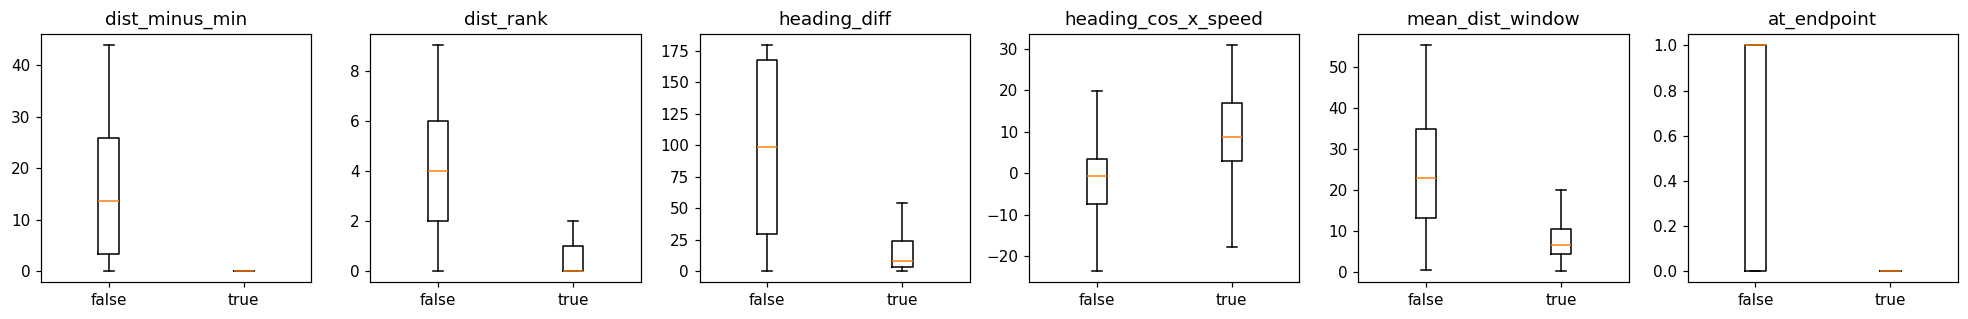

label,0,1
dist_m,21.546,6.727
dist_rank,4.075,0.628
dist_minus_min,15.768,0.662
dist_ratio_min,5.261,0.944
n_cands,8.372,6.403
proj_frac,0.499,0.502
at_endpoint,0.668,0.036
arc_length_m,90.531,211.103
heading_diff,98.484,23.553
heading_valid,0.980,0.982


In [9]:
# features that separate true vs false candidates (train, clean trips)
trc = tr[tr.trip_id.isin(clean.trip_id)].sample(200_000, random_state=0)
show = ["dist_minus_min", "dist_rank", "heading_diff", "heading_cos_x_speed", "mean_dist_window", "at_endpoint"]
fig, axs = plt.subplots(1, len(show), figsize=(18, 3))
for ax, f in zip(axs, show):
    data = [trc.loc[trc.label == 0, f].clip(upper=trc[f].quantile(.98)), trc.loc[trc.label == 1, f].clip(upper=trc[f].quantile(.98))]
    ax.boxplot(data, labels=["false", "true"], showfliers=False); ax.set_title(f)
plt.tight_layout(); plt.savefig("results/plots/feature_separation.png"); plt.show()
trc.groupby("label")[FEATURE_COLUMNS].mean().T.round(3)

**Takeaways.** True candidates are relatively closer (`dist_minus_min` ≈ 0), aligned with the travel direction (`heading_diff` small), and stay close over neighbouring points (`mean_dist_window`). This matches the model importances in notebook 07.